# Importing and initialization

In [49]:
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
from scipy.optimize import curve_fit
import astropy.units as u
from scipy import stats
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors
from astropy.nddata import CCDData
from ccdproc import wcs_project
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture
from photutils.isophote import Ellipse
from photutils.aperture import ApertureStats
from photutils.aperture import EllipticalAnnulus, EllipticalAperture
import math
#importing needed packages

In [2]:
#Functions TAKEN FROM SURFACE PHOTOMETRY LAB. NOT OUR WORK.
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax
def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

def background_meas(imname,data,header,fig,ax,corners,bkg_size=5):
    #need to find ways to select regions of pixels in image
    fig,ax = imdisplay(data,v1perc=1,v2perc=99,logscale=True)

    plt.title(imname)

    #print out the x and y-dimension of the image using the header keywords
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    #the length of each background box size
    #bkg_size = 200

    #make an array whose elements are the different data sections.
    reg = np.array([])


    #specify the different regions.  Each will be appended to the reg array.  the reg array is therefore 3 dimensional.  
    #the first dimension is for each region.  Each of those dimensions contains a 2D array that holds the image section.
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])    #lower left corner
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])    #upper left corner
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    #upper right corner
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1])   #lower right corner

    #print the median and mode of all the pixels. 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)

    #Overlay rectangles with the background region indicated
    rectlist = []
    #loop through all images 
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed
def bkgregplot(data,header,imname, bkgdim, fig, ax):
    #define lower-left corners of each region
    corners = []
    corners.append([0,0])
    corners.append([0,header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim, header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim,0])

    #run the background_meas code to measure the background and plot the background regions
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list,vminperc=40,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
    
        #overplot apertures
        aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])
    
    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
    
        #overplot apertures
        aperiter.plot(ax=ax[1],color='blue')

    ax[0].set_title(galname + ' free ellipse parameters')
    ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav

In [3]:
#initialize dictionaries
imname = {} #list of galaxy images
imname_sub = {} #list of background-subtracted images
data = {} #all data
datag = {} #g band data
datar = {} #r band data
dataz = {} #z band data
header = {} #headers
initparams = {} #initial ellipse parameters
geometry = {} #stores ellipse geometry
ellipse = {}
isolist = {}
xcenav = {}
ycenav = {}
epsav = {}
paav = {}
rhalfasec = {}
rcent = {}
sbcent = {}
sbcent_err = {}
totflux = {}
totflux_err = {}

#unused dictionaries
#datag_sub = {} #background subtracted g band data
#datar_sub = {} #background subtracted r band data
#dataz_sub = {} #background subtracted z band data
#corners = {} #used in location of background areas
#kgdim = {} #size of background measurement
#bkgmodeg = {} #mode of g background
#bkgmoder = {} #mode of r background
#bkgmodez = {} #mode of z background
#bkgmedg = {} #median of g background
#bkgmedr = {} #median of r background
#bkgmedz = {} #median of z background

# Import and set up galaxy images

In [4]:
datadir = '/home/c690j196/ASTR596/Capstone/Data'
os.chdir(datadir)
#set data directory

In [5]:
#import and label all galaxy images
imname['NGC2528'] = 'cutout_121.8537_39.1945.fits'
imname['NGC5527'] = 'cutout_213.6147_36.4035.fits'
imname['NGC5533'] = 'cutout_214.0308_35.3431.fits'
imname['NGC5517'] = 'cutout_213.2140_35.7110.fits'
imname['NGC5568'] = 'cutout_214.8391_35.0922.fits'
imname['IC4446'] = 'cutout_217.2541_37.4633.fits'

In [6]:
#extract all images as arrays
for galname in imname:
    data[galname],header[galname] = fits.getdata(imname[galname], header=True) #extract data and header
    #now separate data by band - we only use g band
    datag[galname] = data[galname][0]
    datar[galname] = data[galname][1]
    dataz[galname] = data[galname][2]

In [7]:
#was unsure if images were background subtracted, so performed a background subtraction as per the lesson to see if the images improved or deteriorated. They deteriorated, so I commented out the relevant code.
#for galname in imname:
    #bkgmodeg[galname],bkgmedg[galname] = bkgregplot(datag[galname],header[galname],imname[galname], bkgdim[galname], fig, ax)
    #bkgmoder[galname],bkgmedr[galname] = bkgregplot(datar[galname],header[galname],imname[galname], bkgdim[galname], fig, ax)
    #bkgmodez[galname],bkgmedz[galname] = bkgregplot(dataz[galname],header[galname],imname[galname], bkgdim[galname], fig, ax)

In [8]:
#for galname in imname: #for each galaxy
    #subtract the background in each band
    #datag_sub[galname] = datag[galname] - bkgmedg[galname]
    #datar_sub[galname] = datar[galname] - bkgmedr[galname]
    #dataz_sub[galname] = dataz[galname] - bkgmedz[galname]

# Find initial parameters (via ds9)

## NGC 2528 initial parameters

In [9]:
initparams['NGC2528']={}
initparams['NGC2528']['xcen']= 132
initparams['NGC2528']['ycen']= 127
initparams['NGC2528']['sma']= 81
initparams['NGC2528']['smina']=47
initparams['NGC2528']['PA']= 0
#guesses from ds9 for the ellipse parameters. Will be refined in the fitting process.

## NGC 5527 initial parameters

In [10]:
initparams['NGC5527']={}
initparams['NGC5527']['xcen']= 143
initparams['NGC5527']['ycen']= 138
initparams['NGC5527']['sma']= 73
initparams['NGC5527']['smina']= 39
initparams['NGC5527']['PA']= 50

## NGC 5533 initial parameters

In [11]:
initparams['NGC5533']={}
initparams['NGC5533']['xcen']= 111
initparams['NGC5533']['ycen']= 139
initparams['NGC5533']['sma']= 80
initparams['NGC5533']['smina']= 48
initparams['NGC5533']['PA']= 115

## NGC 5517 initial parameters

In [12]:
initparams['NGC5517']={}
initparams['NGC5517']['xcen']= 137
initparams['NGC5517']['ycen']= 127
initparams['NGC5517']['sma']= 85
initparams['NGC5517']['smina']= 29
initparams['NGC5517']['PA']= 30

## NGC 5568 initial parameters

In [13]:
initparams['NGC5568']={}
initparams['NGC5568']['xcen']= 134
initparams['NGC5568']['ycen']= 121
initparams['NGC5568']['sma']= 62
initparams['NGC5568']['smina']= 34
initparams['NGC5568']['PA']= 0

## NGC 6260 initial parameters

In [14]:
initparams['NGC6260']={}
initparams['NGC6260']['xcen']= 97
initparams['NGC6260']['ycen']= 123
initparams['NGC6260']['sma']= 56
initparams['NGC6260']['smina']= 43
initparams['NGC6260']['PA']= 90

## IC 4446 initial parameters

In [15]:
initparams['IC4446']={}
initparams['IC4446']['xcen']= 117
initparams['IC4446']['ycen']= 127
initparams['IC4446']['sma']= 80
initparams['IC4446']['smina']= 31
initparams['IC4446']['PA']= 30

# Identify apertures

## Get ellipse geometry:

0.027894152328372 1.3178313382863722
0.003343495773151517 1.4158214855193116
0.05580124258995056 5.810456476211445
0.008702358230948448 2.110839295029585
0.0023258747532963753 1.1005233101247764
0.0007110752630978823 0.23496548029779799


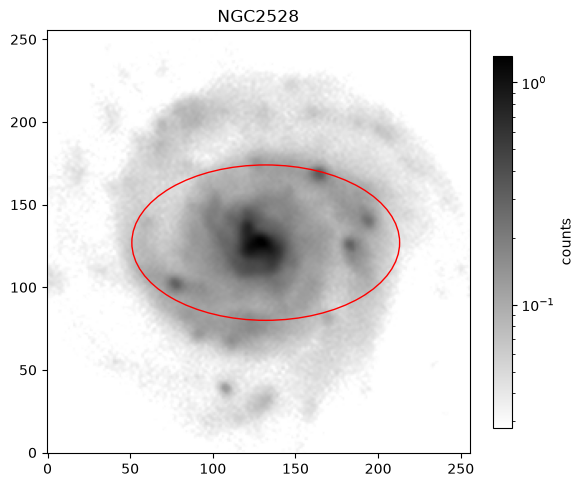

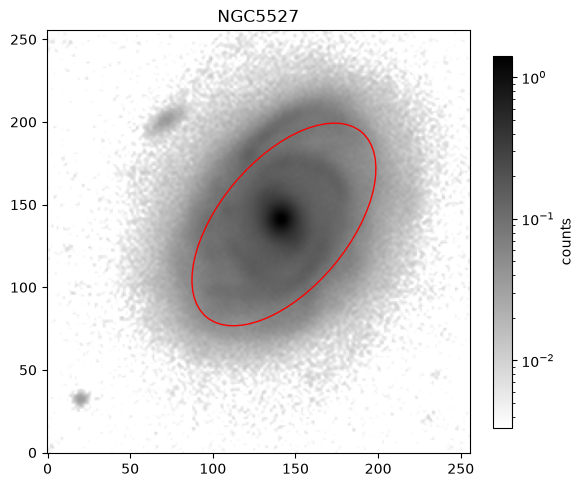

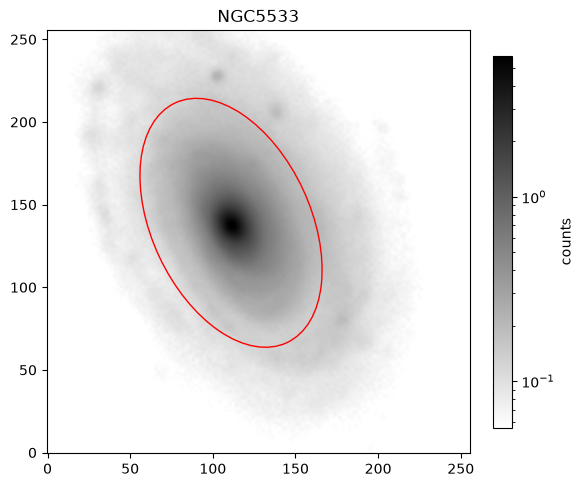

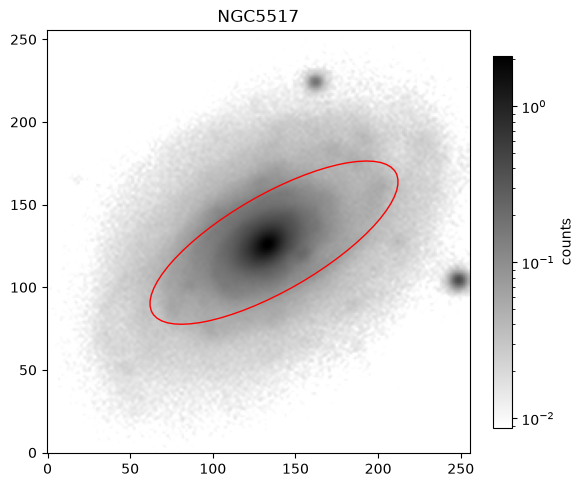

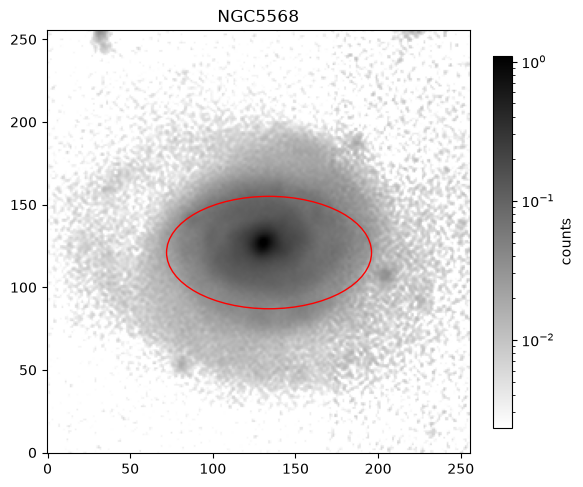

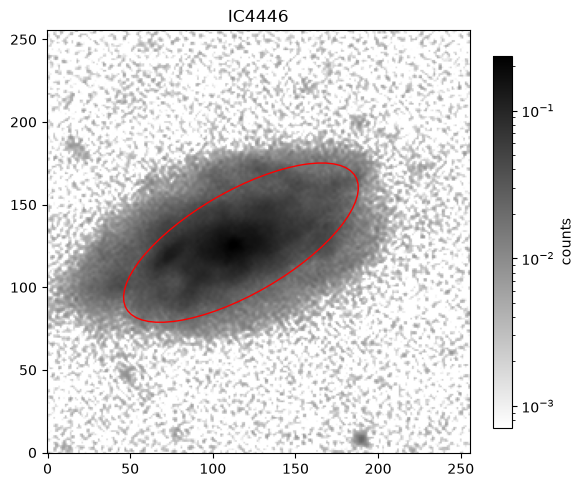

In [16]:
for galname in imname:
    initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma']
    #calculates ellipticity for each galacy
    geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians
    #generates an elipse for each object
    aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)#plot our image
    #fig,ax = plt.subplots(figsize=(6,6))
    fig,ax = imdisplay(datag[galname],v1perc=40,v2perc=99.99,logscale=True)
    aper.plot(color='red')
    plt.title(galname)
    #displays ellipse

## Get aperture geometry:

v1 =  0.03, v2 =  1.32
v1 =  0.00, v2 =  1.42
v1 =  0.06, v2 =  5.81
v1 =  0.01, v2 =  2.11
v1 =  0.00, v2 =  1.10
v1 =  0.00, v2 =  0.23


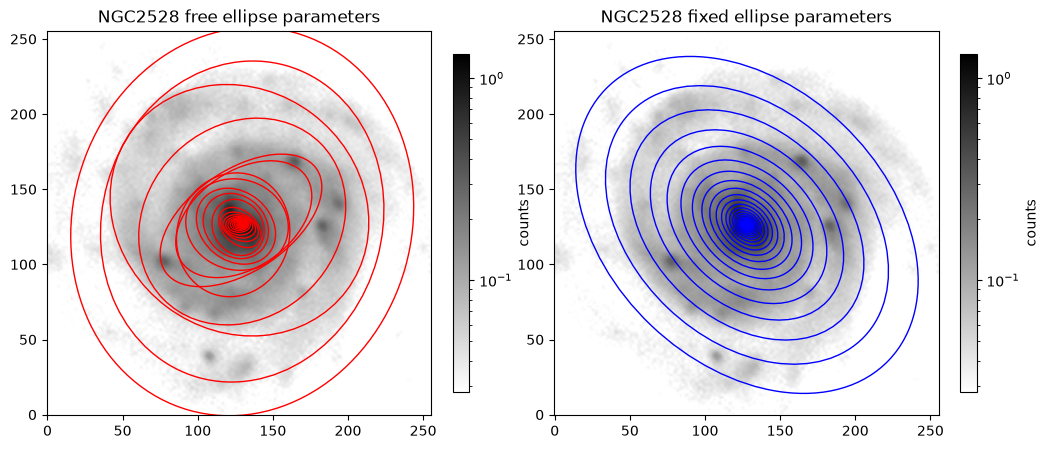

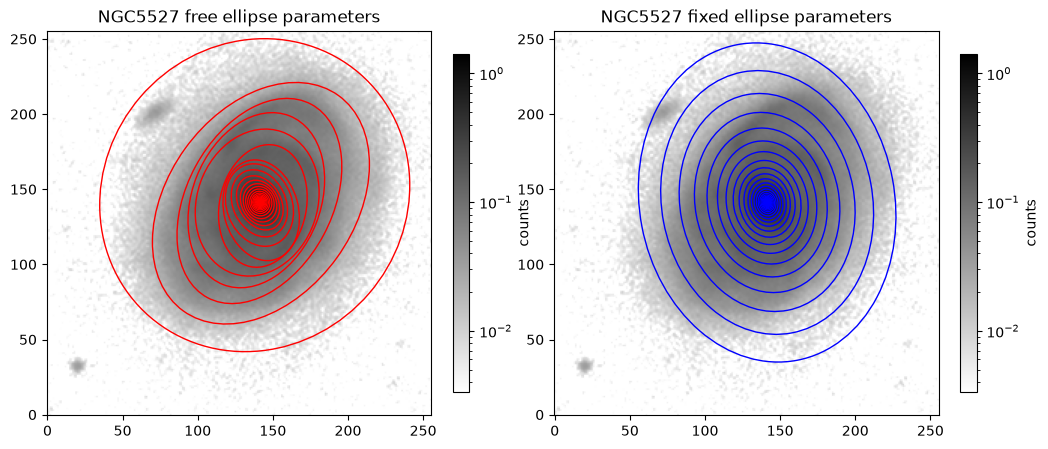

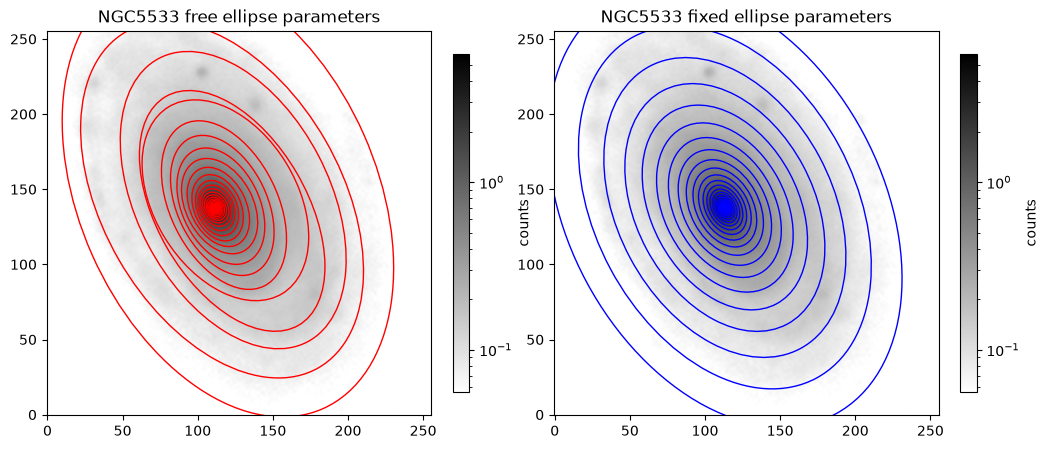

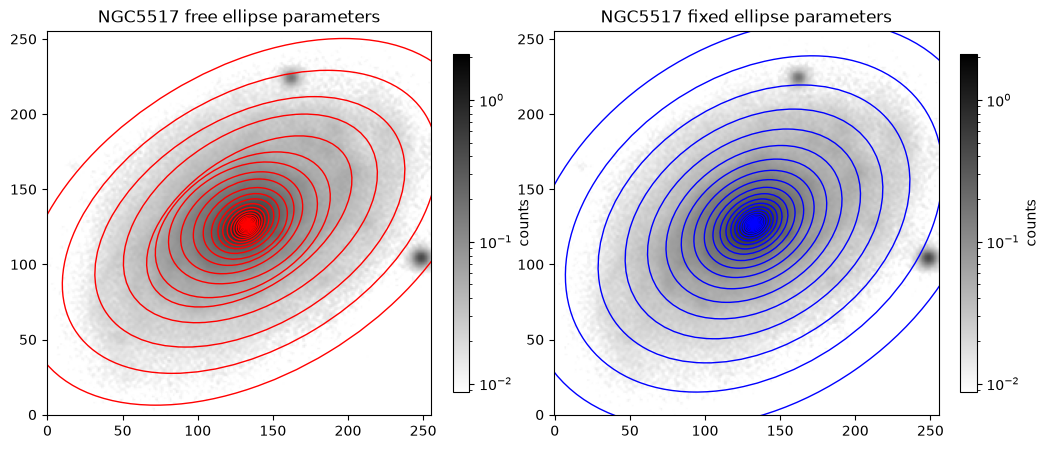

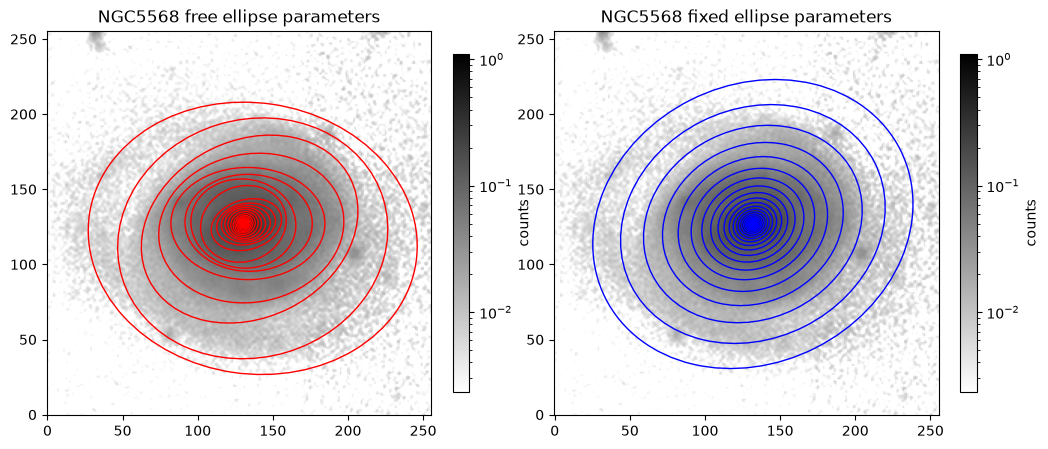

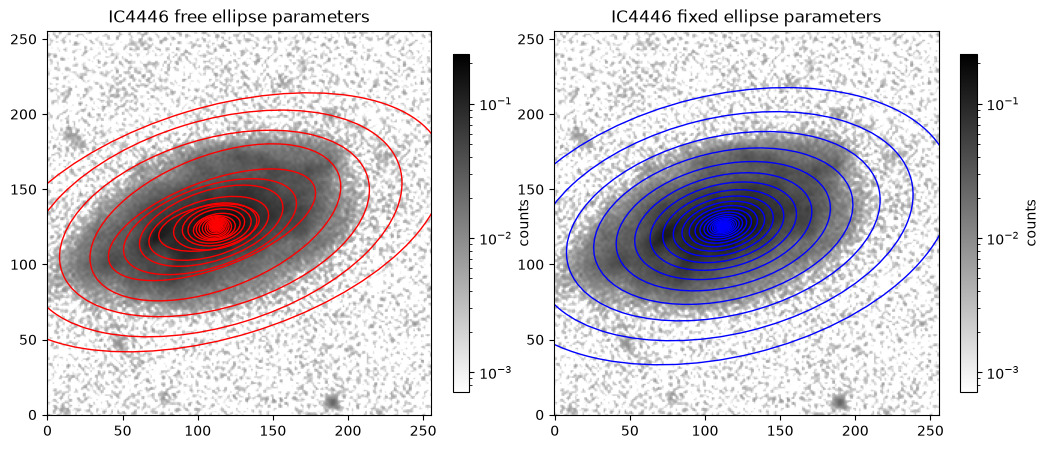

In [17]:
for galname in imname:
    ellipse[galname] = Ellipse(datag[galname], geometry[galname])
    #stores first ellipse as an object
    isolist[galname] = ellipse[galname].fit_image()
    #layers isophotes onto fitst ellipse
    xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, datag[galname],isolist[galname])
    #plots all isophotes and returns info about them

# Find central surface brightness

In [25]:
#these values are found using code in the next cell, but must be stored here for the loop to run correctly. They are the values of the half-light radius taken from plots below.
rhalfasec['NGC2528']=16
rhalfasec['NGC5527']=11
rhalfasec['NGC5533']=14.5
rhalfasec['NGC5517']=10.5
rhalfasec['NGC5568']=9.25
rhalfasec['IC4446']=12

the half-light radius = 16.000 [asec]
the central surface brightness is = 0.798 [mag/asec^2]
the half-light radius = 11.000 [asec]
the central surface brightness is = 0.645 [mag/asec^2]
the half-light radius = 14.500 [asec]
the central surface brightness is = -0.831 [mag/asec^2]
the half-light radius = 10.500 [asec]
the central surface brightness is = 0.214 [mag/asec^2]
the half-light radius = 9.250 [asec]
the central surface brightness is = 0.984 [mag/asec^2]
the half-light radius = 12.000 [asec]
the central surface brightness is = 2.601 [mag/asec^2]


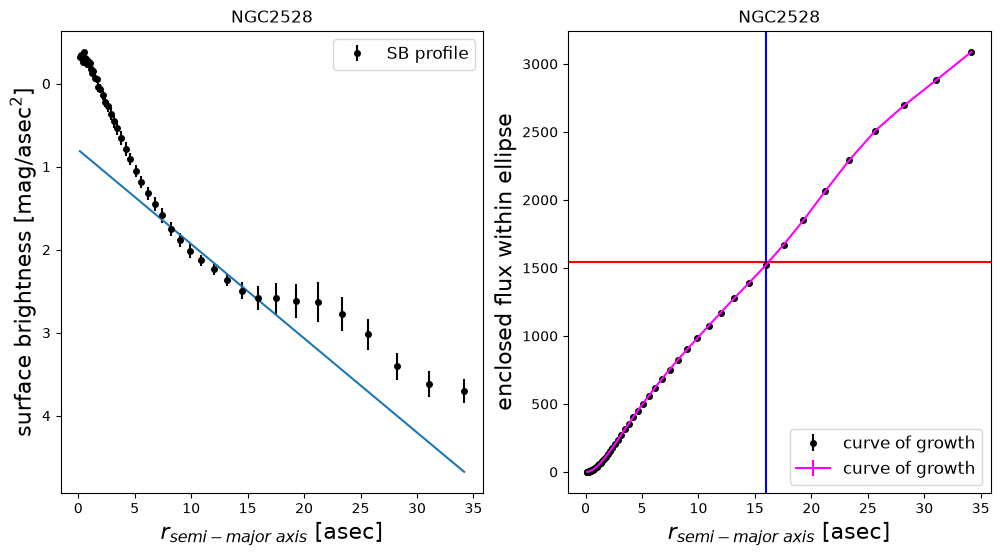

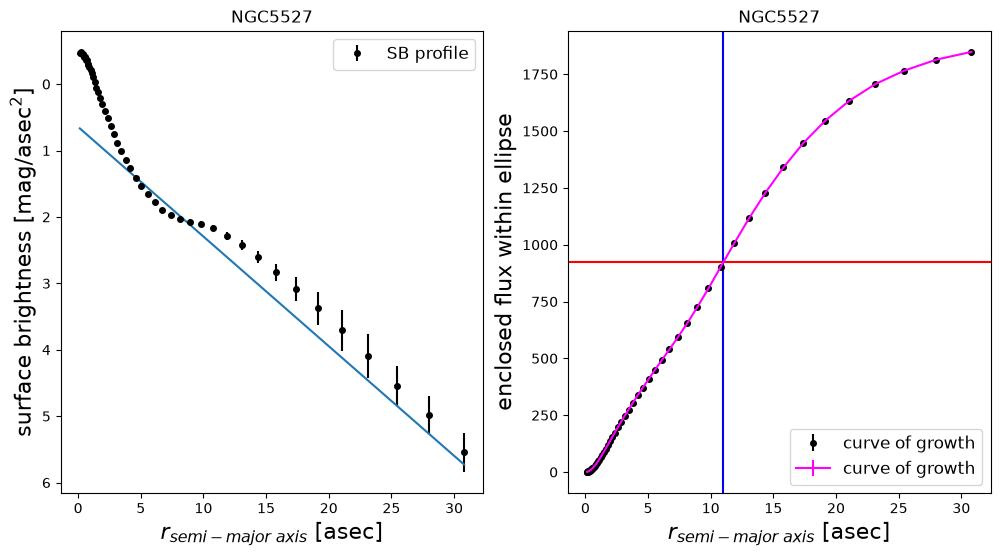

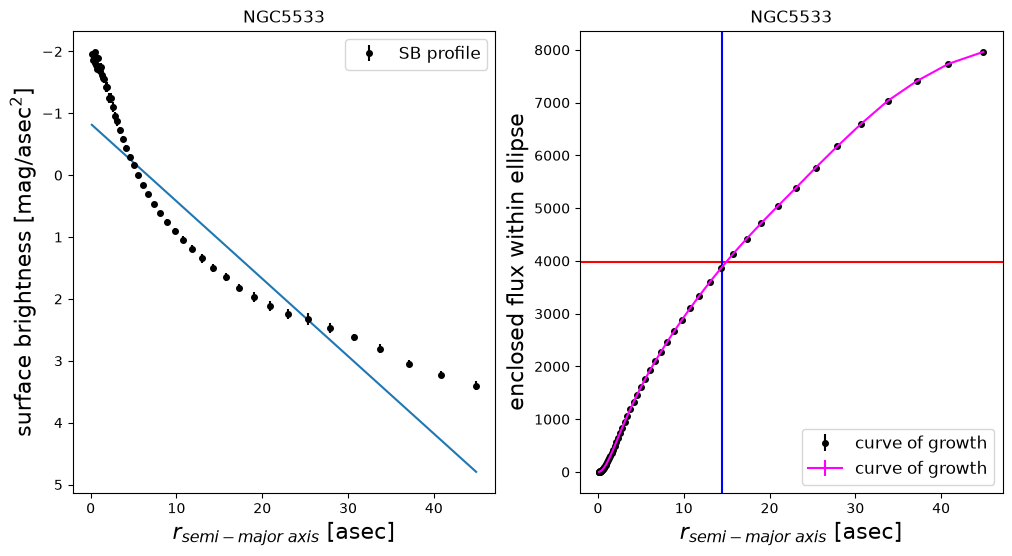

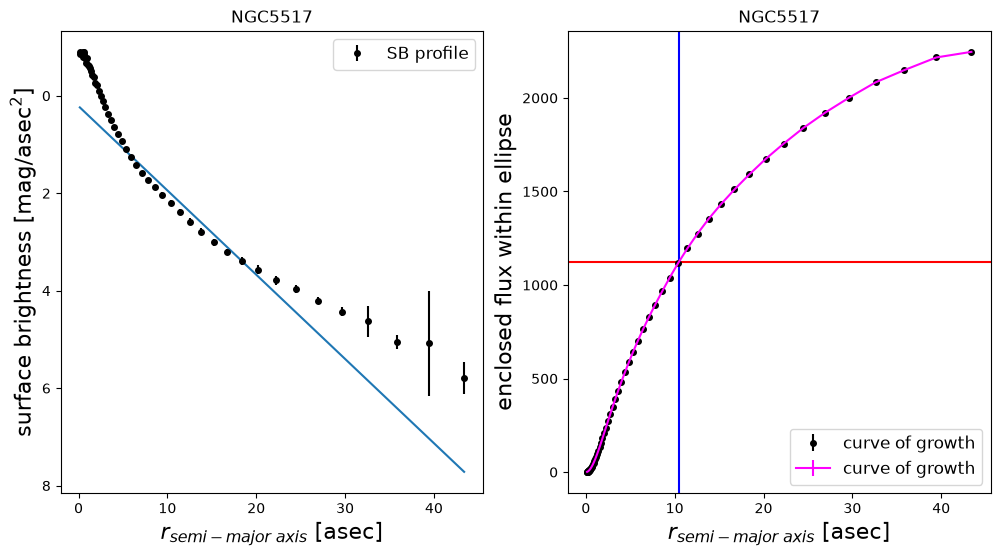

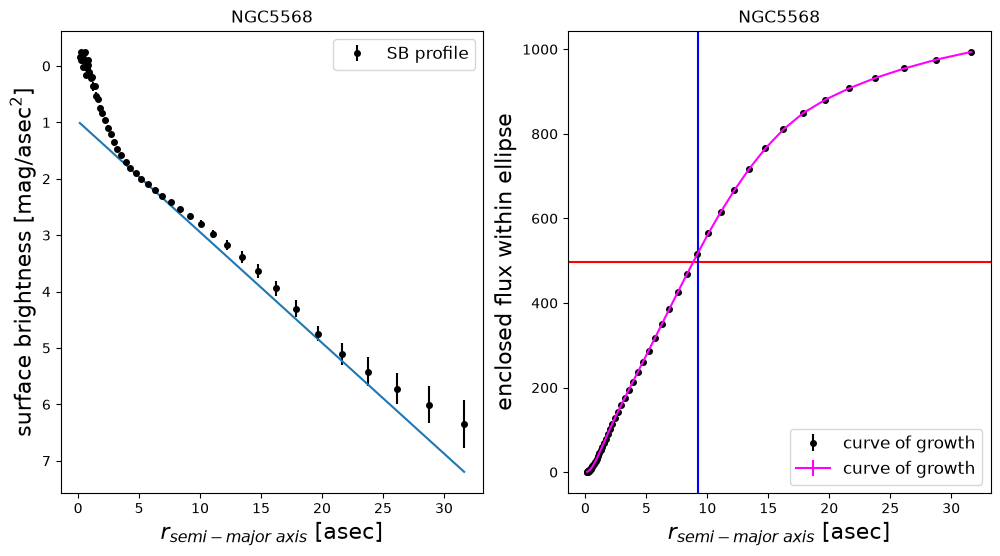

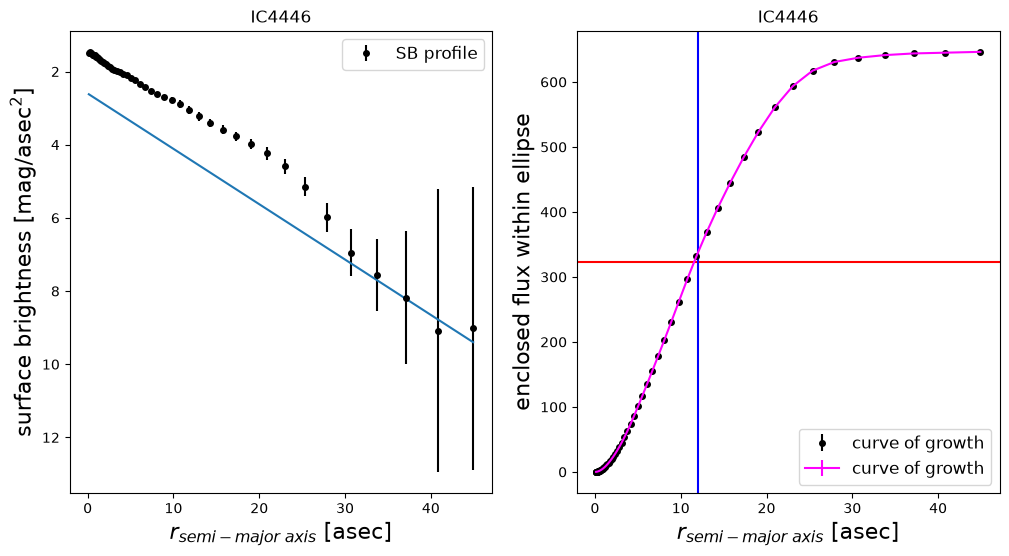

In [51]:
for galname in imname:
    pixscale = header[galname]['CD2_2'] * 3600
    rcent[galname] = np.array([])
    sbcent[galname] = np.array([])
    sbcent_err[galname] = np.array([])
    totflux[galname] = np.array([])
    totflux_err[galname] = np.array([])
    #initialize output values
    for aindx, a_out in enumerate(isolist[galname].sma):
        #for each sma in the list (except the first)
        if aindx==0:
            a_in = 0.01
        if aindx>0:
            #create the inner and outer minor axes from the major axes and ellipticity
            b_out = a_out * (1.-epsav[galname])
            b_in = a_in * (1.-epsav[galname])
            #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
            #set up elliptical annuli
            annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
            #store entire ellipses
            total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
            #get statistics about ellipses and annuli
            aperstats_ann = ApertureStats(datag[galname],annulus_aperture)
            aperstats_tot = ApertureStats(datag[galname],total_aperture)
            a_in = a_out
            #the central radius of each annulus/ellipse in asec
            rcent[galname] = np.append(rcent[galname], (a_in + a_out) / 2.*pixscale)
            #the average pixel flux within each annulus
            avflux = aperstats_ann.mean
            #the standard deviation of the pixel values within each annulus
            stdflux = aperstats_ann.std
            #the number of pixels in each annulus
            numpix = aperstats_ann.sum_aper_area
            #adds each annulus to the value for the previous ones to form totals
            totflux[galname] = np.append(totflux[galname],aperstats_tot.sum)
            #error of above value
            totflux_err[galname]= np.append(totflux_err[galname],aperstats_tot.std)
            #the area of a pixel
            pixarea = pixscale*4
            #surface brightness in magnitudes of each annulus
            sbcent[galname] = np.append(sbcent[galname], -2.5*np.log10(avflux*pixarea))
            #propagated error of above
            sbcent_err[galname] = np.append(sbcent_err[galname], stdflux/(avflux*np.log(10))) #pixel area factor cancels out
            
    fig,ax = plt.subplots(1,2,figsize=(12, 6))
    #plot the semi-major axis vs. magnitude
    ax[0].errorbar(rcent[galname], sbcent[galname], yerr=sbcent_err[galname], 
             fmt='o', markersize=4, color='black', label='SB profile')
    ax[0].invert_yaxis()
    ax[0].legend(fontsize=12)
    ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
    ax[0].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
    ax[0].set_title(galname)
    #plot the curve of growth (used to idenfity rhalfasec)
    ax[1].errorbar(rcent[galname], totflux[galname], yerr=totflux_err[galname], 
             fmt='o', markersize=4, color='black', label='curve of growth')
    ax[1].errorbar(rcent[galname], totflux[galname], yerr=totflux_err[galname], 
             fmt='-', markersize=4, color='magenta', label='curve of growth')
    ax[1].legend(fontsize=12)
    ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
    ax[1].set_ylabel('enclosed flux within ellipse',fontsize=16)
    ax[1].set_title(galname)
    #make line indicating half of all light. Crosses the curve of growth at the half-light radius
    ax[1].axhline(totflux[galname][-1]/2., color='red')
    #makes line indicate half-light radius based on chosen value. Is manually moved until it intersects the curve of growth and half-light line
    #ensuring that it must be the actual half-light radius
    ax[1].axvline(rhalfasec[galname], color='blue', label='r_half')
    print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')
    #To get a fit for the disc, we assume an n=1 Sersic profile - that is, a straight line in magnitudes. We can write it in terms of the half-light radius and its intensity
    #and then find the value at zero to get the central surface brightness of the disc
    #check for nan values - increment up if nan
    if np.isnan(sbcent[galname][int(rhalfasec[galname])]) == True:
        sbhalf = sbcent[galname][int(rhalfasec[galname]+2)]
    else:
        sbhalf = sbcent[galname][int(rhalfasec[galname])]
    sb0 = sbhalf - 2.5*np.log10(1/np.exp(1))
    print(f'the central surface brightness is = {sb0:.3f} [mag/asec^2]')
    #This formula doesn't look like the standard Sersic profile equation because it has been converted to be a function of magnitudes rather than linear intensities (or in this case, surface brightnesses)
    cons=-2.5*1.672*np.log10(np.exp(1))/rhalfasec[galname]
    ax[0].plot(rcent[galname],sb0-rcent[galname]*cons, label='Profile')
